# Chapitre 1 - Cours 5 : données, droit et société

Le dernier compromis du chapitre ne se joue pas entre deux technologies, mais entre les
besoins d'une entreprise et les droits des personnes dont elle traite les données. Le
livre insiste : les contraintes légales influencent désormais les **fondations** de la
conception des systèmes de données. Ce notebook couvre la section *Data Systems, Law, and
Society* et montre, par des expériences, pourquoi des exigences juridiques simples à
énoncer sont difficiles à implémenter.

**Plan.**

1. Une responsabilité qui dépasse l'entreprise : RGPD, décisions automatisées, et ce
   que cela implique techniquement.
2. Le droit à l'effacement face aux journaux immuables : compaction ou effacement
   cryptographique.
3. Effacer aussi les données dérivées : combien de temps une donnée survit-elle ?
4. La minimisation des données : coûts cachés du stockage, réidentification,
   pseudonymisation.
5. Résidence des données et normes du secteur.

In [1]:
import hashlib

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Une responsabilité qui dépasse l'entreprise (section *Data Systems, Law, and Society*)

Servir les besoins de son entreprise ne suffit plus : les ingénieurs de données ont aussi
une responsabilité envers la société. Deux constats du livre :

- **la loi** : depuis 2018, le RGPD (règlement général sur la protection des données,
  GDPR en anglais) donne aux résidents de nombreux pays européens davantage de contrôle et
  de droits sur leurs données personnelles ; des réglementations proches existent ailleurs
  (le CCPA en Californie), et les règles sur l'IA (le règlement européen sur l'IA)
  encadrent encore davantage l'usage des données personnelles ;
- **les effets sur les personnes**, même hors réglementation : les réseaux sociaux
  changent la manière de s'informer, donc les opinions et peut-être les élections ; des
  systèmes automatisés décident qui obtient un prêt, une assurance, un entretien
  d'embauche, ou qui est suspecté d'un délit.

Personne n'a besoin de devenir juriste, mais une culture de base en droit et en éthique
est aussi importante, selon le livre, qu'une culture de base en systèmes distribués. Le
schéma ci-dessous relie quelques principes juridiques aux mécanismes techniques qu'ils
exigent, et que les chapitres suivants permettent de construire.

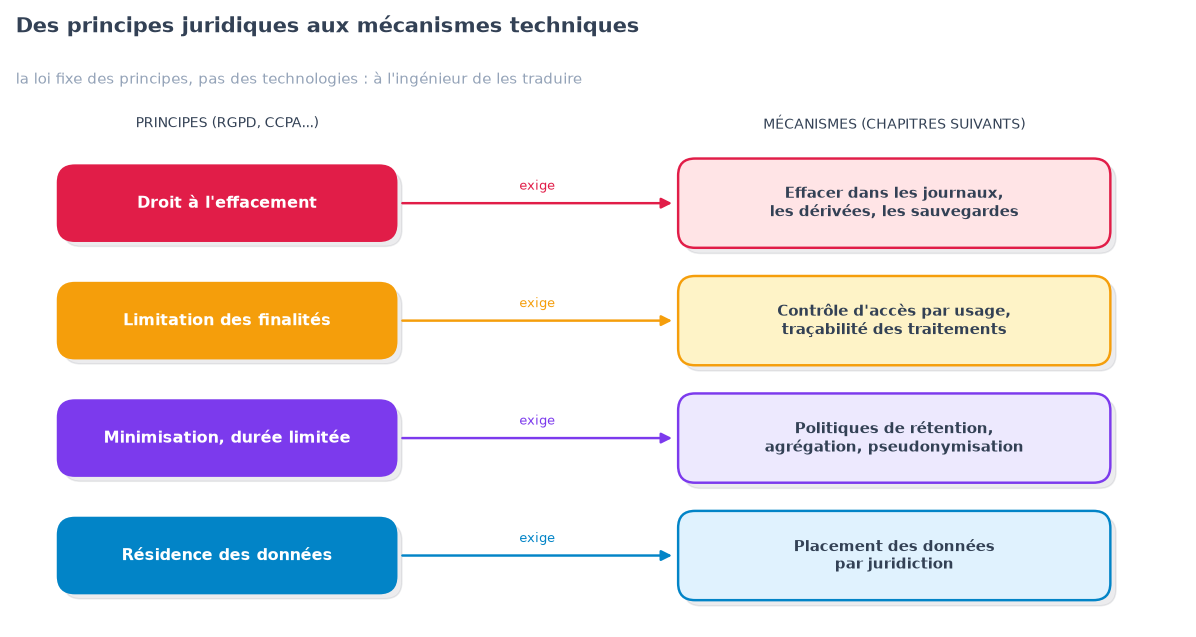

In [2]:
d = Diagram(12.5, 5.6, title="Des principes juridiques aux mécanismes techniques",
            subtitle="la loi fixe des principes, pas des technologies : à l'ingénieur de les traduire")
law = [("eff", "Droit à l'effacement", ROSE), ("fin", "Limitation des finalités", AMBER),
       ("min", "Minimisation, durée limitée", VIOLET), ("res", "Résidence des données", SKY)]
tech = [("t_eff", "Effacer dans les journaux,\nles dérivées, les sauvegardes"), ("t_fin", "Contrôle d'accès par usage,\ntraçabilité des traitements"),
        ("t_min", "Politiques de rétention,\nagrégation, pseudonymisation"), ("t_res", "Placement des données\npar juridiction")]
for i, ((k, t, c), (k2, t2)) in enumerate(zip(law, tech)):
    y = 4.5 - i * 1.25
    d.box(k, 2.3, y, t, color=c, w=3.6, h=0.8, filled=True)
    d.box(k2, 9.4, y, t2, color=c, w=4.6, h=0.95, fontsize=9.5)
    d.arrow(k, k2, "exige", color=c)
d.note(2.3, 5.35, "PRINCIPES (RGPD, CCPA...)", color=SLATE, style="normal")
d.note(9.4, 5.35, "MÉCANISMES (CHAPITRES SUIVANTS)", color=SLATE, style="normal")
d.show()

Le livre souligne qu'il n'existe pas aujourd'hui de liste claire des technologies ou
architectures « conformes au RGPD » : le règlement énonce volontairement des principes
généraux, sujets à interprétation, pour ne pas dépendre d'une technologie vite dépassée.
La conformité n'a donc pas de réponse simple ; regardons les cas les plus techniques.

> **À retenir.** Les systèmes de données sont soumis au droit (RGPD, CCPA, règles sur l'IA)
> et ont des effets sociaux réels. La loi fixe des principes ; les traduire en mécanismes
> techniques est un travail d'ingénierie, souvent difficile.